# Topic 4: Consumption Optimization -- Figure Generator

Regenerates the static figures in
[`slides/04_consumption-optimization/deck.qmd`](../slides/04_consumption-optimization/deck.qmd).
Same conventions as the Topic 3 figure notebook: navy/amber palette, serif type,
150 dpi, saved to `../slides/04_consumption-optimization/figs/`.

Running example, chosen to mirror Topic 3's firm: $u = \sqrt{xy}$, prices
$p_x = 12$, $p_y = 3$, income $I = 480$. The consumer buys $x = 20$, $y = 80$
and reaches $u = 40$; reaching $u = 40$ at least cost takes exactly 480.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

NAVY = "#24325c"
AMBER = "#b8842a"
GREY = "#8a8a8a"
plt.rcParams.update({"font.family": "serif", "font.size": 12,
                     "axes.edgecolor": "#333333", "axes.labelcolor": "#222222"})
FIGDIR = Path("../slides/04_consumption-optimization/figs")
FIGDIR.mkdir(parents=True, exist_ok=True)

def savefig(fig, name):
    path = FIGDIR / name
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print(f"saved {path}")

PX, PY, I = 12.0, 3.0, 480.0

## A gallery of preferences

saved ..\slides\04_consumption-optimization\figs\preference-gallery.png


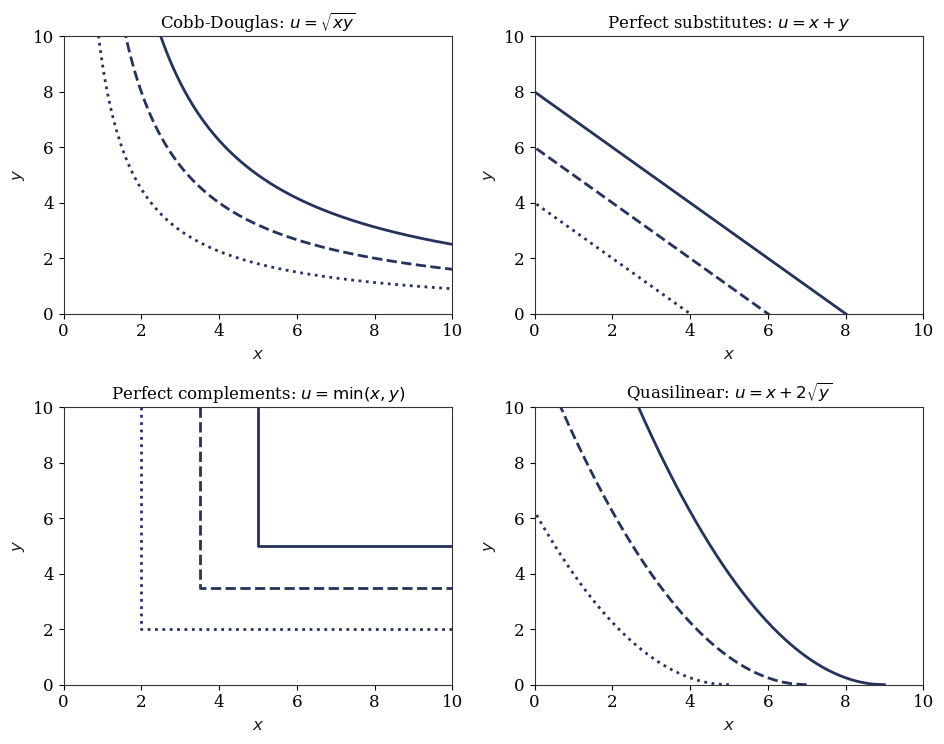

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(9.6, 7.6))
x = np.linspace(0.05, 10, 400)
styles = [":", "--", "-"]

ax = axes[0, 0]
for u, s in zip((3, 4, 5), styles):
    ax.plot(x, u**2 / x, color=NAVY, lw=2, ls=s)
ax.set_title(r"Cobb-Douglas: $u = \sqrt{xy}$", fontsize=12)

ax = axes[0, 1]
for u, s in zip((4, 6, 8), styles):
    ax.plot(x, u - x, color=NAVY, lw=2, ls=s)
ax.set_title(r"Perfect substitutes: $u = x + y$", fontsize=12)

ax = axes[1, 0]
for u, s in zip((2, 3.5, 5), styles):
    ax.plot([u, u, 10], [10, u, u], color=NAVY, lw=2, ls=s)
ax.set_title(r"Perfect complements: $u = \min(x, y)$", fontsize=12)

ax = axes[1, 1]
yy = np.linspace(0, 10, 400)
for u, s in zip((5, 7, 9), styles):
    xx = u - 2 * np.sqrt(yy)
    ok = xx >= 0
    ax.plot(xx[ok], yy[ok], color=NAVY, lw=2, ls=s)
ax.set_title(r"Quasilinear: $u = x + 2\sqrt{y}$", fontsize=12)

for ax in axes.flat:
    ax.set_xlim(0, 10); ax.set_ylim(0, 10)
    ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
fig.tight_layout()
savefig(fig, "preference-gallery.png")
plt.show()

## Utility maximization: the tangency

saved ..\slides\04_consumption-optimization\figs\consumer-tangency.png


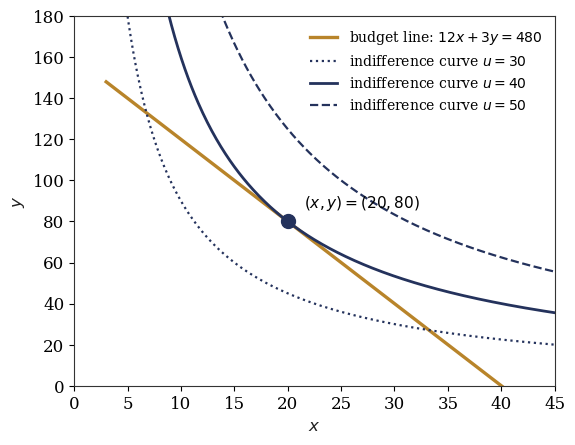

In [3]:
fig, ax = plt.subplots(figsize=(6.2, 4.8))
x = np.linspace(3, 45, 400)
ax.plot(x, (I - PX * x) / PY, color=AMBER, lw=2.4, label="budget line: $12x + 3y = 480$")
for u, s in [(30, ":"), (40, "-"), (50, "--")]:
    ax.plot(x, u**2 / x, color=NAVY, lw=2.0 if u == 40 else 1.6, ls=s,
            label=f"indifference curve $u = {u}$")
ax.plot(20, 80, "o", color=NAVY, ms=10, zorder=6)
ax.annotate("$(x, y) = (20, 80)$", (20, 80), textcoords="offset points",
            xytext=(12, 10), fontsize=11)
ax.set_xlim(0, 45); ax.set_ylim(0, 180)
ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
ax.legend(frameon=False, fontsize=10, loc="upper right")
savefig(fig, "consumer-tangency.png")
plt.show()

## Expenditure minimization: the dual tangency

saved ..\slides\04_consumption-optimization\figs\expenditure-min.png


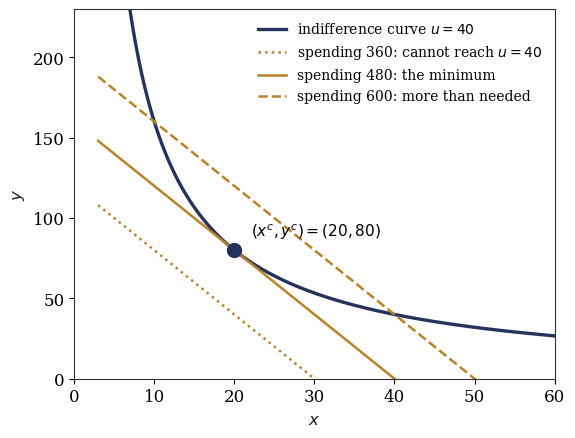

In [4]:
fig, ax = plt.subplots(figsize=(6.2, 4.8))
x = np.linspace(3, 60, 400)
ax.plot(x, 1600 / x, color=NAVY, lw=2.4, label=r"indifference curve $u = 40$")
for E, s, lab in [(360, ":", "spending 360: cannot reach $u = 40$"),
                  (480, "-", "spending 480: the minimum"),
                  (600, "--", "spending 600: more than needed")]:
    ax.plot(x, (E - PX * x) / PY, color=AMBER, lw=1.8, ls=s, label=lab)
ax.plot(20, 80, "o", color=NAVY, ms=10, zorder=6)
ax.annotate("$(x^c, y^c) = (20, 80)$", (20, 80), textcoords="offset points",
            xytext=(12, 10), fontsize=11)
ax.set_xlim(0, 60); ax.set_ylim(0, 230)
ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
ax.legend(frameon=False, fontsize=10, loc="upper right")
savefig(fig, "expenditure-min.png")
plt.show()

## The lump sum principle

A tax of 36 on each unit of $x$ raises $p_x$ to 48. The consumer buys 5 units,
so the tax raises 180, and utility falls to 20. Taking the same 180 as a lump
sum leaves income 300 at the old prices: the new budget line passes through the
taxed bundle (5, 80), and the consumer does better, reaching 25 at (12.5, 50).

saved ..\slides\04_consumption-optimization\figs\lump-sum-principle.png


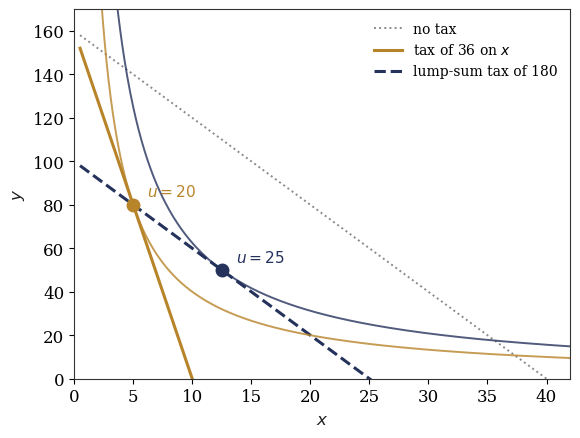

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 4.8))
x = np.linspace(0.5, 42, 500)
ax.plot(x, (480 - 12 * x) / 3, color=GREY, lw=1.4, ls=":", label="no tax")
ax.plot(x, (480 - 48 * x) / 3, color=AMBER, lw=2.2, label="tax of 36 on $x$")
ax.plot(x, (300 - 12 * x) / 3, color=NAVY, lw=2.2, ls="--", label="lump-sum tax of 180")
ax.plot(x, 400 / x, color=AMBER, lw=1.4, alpha=0.8)
ax.plot(x, 625 / x, color=NAVY, lw=1.4, alpha=0.8)
ax.plot(5, 80, "o", color=AMBER, ms=9, zorder=6)
ax.plot(12.5, 50, "o", color=NAVY, ms=9, zorder=6)
ax.annotate("$u = 20$", (5, 80), textcoords="offset points", xytext=(10, 6), fontsize=11, color=AMBER)
ax.annotate("$u = 25$", (12.5, 50), textcoords="offset points", xytext=(10, 6), fontsize=11, color=NAVY)
ax.set_xlim(0, 42); ax.set_ylim(0, 170)
ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
ax.legend(frameon=False, fontsize=10, loc="upper right")
savefig(fig, "lump-sum-principle.png")
plt.show()